In [ ]:

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE = "#4472C4"

import os
import psycopg2
from dotenv import load_dotenv

load_dotenv()

conn = psycopg2.connect(
    host=os.environ["DB_HOST"],
    port=os.environ["DB_PORT"],
    dbname=os.environ["DB_NAME"],
    user=os.environ["DB_USER"],
    password=os.environ["DB_PASSWORD"],
)


def load_dataframe(table_name, conn, schema=None, preserve_case=False):
    from psycopg2 import sql
    if not isinstance(table_name, str) or not table_name.strip():
        raise ValueError("table_name must be a nonempty SQL table name")
    name = table_name if preserve_case else table_name.lower()
    identifier = sql.Identifier(schema, name) if schema else sql.Identifier(name)
    with conn.cursor() as cur:
        cur.execute(sql.SQL("SELECT * FROM {}").format(identifier))
        return pd.DataFrame(cur.fetchall(), columns=[c[0] for c in cur.description])


def _frame(data, conn=None, schema=None, preserve_case=False):
    if isinstance(data, pd.DataFrame):
        return data.copy()
    if isinstance(data, str):
        if conn is None:
            raise ValueError("Pass conn=your_connection when data is a SQL table name")
        return load_dataframe(data, conn, schema, preserve_case)
    raise TypeError("data must be a pandas DataFrame or a SQL table name")


def _finish(fig, output_dir, filename):
    if output_dir is not None:
        folder = Path(output_dir)
        folder.mkdir(parents=True, exist_ok=True)
        fig.savefig(folder / filename, dpi=300, bbox_inches="tight")
    return fig


def missing_summary(data, **source):
    #Per column: dtype, missing count/share, and unique nonmissing values
    d = _frame(data, **source)
    return pd.DataFrame({"dtype": d.dtypes.astype(str), "n_missing": d.isna().sum(),
                         "share_missing": d.isna().mean(), "n_unique": d.nunique()})


def quantity_summary(data, by="bc_prescribed", **source):
    #Count and numeric summary of quantity per group; retain missing groups
    d = _frame(data, **source)
    return d.groupby(by, dropna=False)["quantity"].agg(
        ["count", "mean", "median", "std", "min", "max"])


def monthly_counts(data, date_col="date_order_placed", **source):
    #Records per calendar month, including zero months within the date span
    dates = pd.to_datetime(_frame(data, **source)[date_col], errors="coerce")
    counts = dates.dt.to_period("M").value_counts().sort_index()
    if not counts.empty:
        counts = counts.reindex(pd.period_range(counts.index.min(), counts.index.max(), freq="M"), fill_value=0)
    return counts.rename_axis("month").reset_index(name="n_records")


def prescriptions_per_patient(data, patient_col="patient_id", **source):
    #RxWritten row count per nonmissing patient ID
    d = _frame(data, **source)
    return d.groupby(patient_col).size().rename("n_prescriptions").reset_index()


def customer_ages(data, as_of=None, patient_col="patient_id", dob_col="customer_dob", **source):
    #Age per patient at as_of (today by default), using first DOB as in notebook

    #Missing patient IDs are excluded
    # Invalid DOBs become missing ages

    d = _frame(data, **source).dropna(subset=[patient_col])
    d[dob_col] = pd.to_datetime(d[dob_col], errors="coerce")
    if d.groupby(patient_col)[dob_col].nunique().gt(1).any():
        raise ValueError("Conflicting DOBs for a patient; resolve before calculating ages")
    d = d[[patient_col, dob_col]].drop_duplicates(patient_col).copy()
    date = pd.Timestamp.today().normalize() if as_of is None else pd.Timestamp(as_of).normalize()
    dob = d[dob_col]
    pending = (dob.dt.month > date.month) | ((dob.dt.month == date.month) & (dob.dt.day > date.day))
    d["age"] = (date.year - dob.dt.year - pending.astype(int)).astype("Int64")
    #Future DOBs remain visible as negative ages
    return d


def time_delays(data, start_col, end_col, unit="hours", **source):

    seconds = {"days": 86400, "hours": 3600, "minutes": 60}
    if unit not in seconds:
        raise ValueError("unit must be 'days', 'hours', or 'minutes'")
    d = _frame(data, **source)
    start = pd.to_datetime(d[start_col], errors="coerce")
    end = pd.to_datetime(d[end_col], errors="coerce")
    d[f"delay_{unit}"] = (end - start).dt.total_seconds() / seconds[unit]
    return d


def plot_histogram(data, column, hue=None, bins="auto", binwidth=None,
                   discrete=False, title=None, xlabel=None, ylabel="Number of records",
                   color=BLUE, xlim=None, output_dir="EDA", filename=None, **source):
    """Histogram of a column, optionally grouped; xlim changes view only."""
    d = _frame(data, **source)
    fig, ax = plt.subplots(figsize=(10, 6))
    if d[column].notna().any():
        # Give constant-valued inputs a real bin span
        if binwidth is not None:
            if binwidth <= 0:
                raise ValueError("binwidth must be positive")
            values = d[column].dropna()
            if values.min() == values.max():
                bins = [float(values.min()) - binwidth / 2,
                        float(values.max()) + binwidth / 2]
                binwidth = None
        sns.histplot(data=d, x=column, hue=hue, bins=bins, binwidth=binwidth,
                     discrete=discrete, color=color, ax=ax)
    else:
        ax.text(.5, .5, "No nonmissing values", transform=ax.transAxes, ha="center")
    ax.set(title=title or column, xlabel=xlabel or column, ylabel=ylabel)
    if xlim is not None:
        ax.set_xlim(xlim)
    fig.tight_layout()
    return _finish(fig, output_dir, filename or f"hist_{column}{'_by_' + hue if hue else ''}.png")


def plot_refills(data, kind="hist", output_dir="EDA", **source):
    #Refills allowed per order
    #Full range shown
    if kind == "hist":
        return plot_histogram(data, "refills_allowed", discrete=True,
                              title="Refills allowed per order", xlabel="Refills allowed",
                              ylabel="Number of orders", output_dir=output_dir, **source)
    if kind != "box":
        raise ValueError("kind must be 'hist' or 'box'")
    values = _frame(data, **source)["refills_allowed"].dropna()
    fig, ax = plt.subplots(figsize=(8, 6))
    if not values.empty:
        ax.boxplot(values)
    else:
        ax.text(.5, .5, "No nonmissing values", transform=ax.transAxes, ha="center")
    ax.set(title="Refills allowed per order", ylabel="Refills allowed")
    fig.tight_layout()
    return _finish(fig, output_dir, "boxplot_refills.png")


def plot_quantity(data, by_bc=False, **kwargs):
    #Quantity distribution per order, optionally grouped by birth-control flag
    return plot_histogram(data, "quantity", hue="bc_prescribed" if by_bc else None,
                          title="Quantity prescribed", xlabel="Quantity",
                          ylabel="Number of orders", **kwargs)


def plot_category_counts(data, column, title=None, output_dir="EDA", filename=None, **source):
    #Record counts per observed category; missing values have a separate bar
    counts = _frame(data, **source)[column].value_counts(dropna=False)
    labels = ["(missing)" if pd.isna(v) else str(v) for v in counts.index]
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(range(len(counts)), counts.values, color=BLUE)
    ax.set_xticks(range(len(counts)), labels, rotation=45, ha="right")
    ax.set(title=title or f"Record count by {column}", xlabel=column, ylabel="Number of records")
    fig.tight_layout()
    return _finish(fig, output_dir, filename or f"counts_{column}.png")


def plot_monthly_orders(data, date_col="date_order_placed", output_dir="EDA", **source):
    #Orders placed per month, preserving year and including zero months
    counts = monthly_counts(data, date_col, **source)
    fig, ax = plt.subplots(figsize=(12, 6))
    ax.bar(counts["month"].astype(str), counts["n_records"], color=BLUE)
    ax.set(title="Orders placed by month", xlabel="Month", ylabel="Number of orders")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    fig.tight_layout()
    return _finish(fig, output_dir, "orders_by_month.png")


def plot_prescriptions_per_patient(data, grouped=False, output_dir="EDA", **source):
    #RxWritten records per patient, or one vs multiple prescriptions
    counts = prescriptions_per_patient(data, **source)
    if not grouped:
        return plot_histogram(counts, "n_prescriptions", discrete=True,
                              title="Prescriptions written per patient", xlabel="Prescriptions",
                              ylabel="Number of patients", output_dir=output_dir)
    n = counts["n_prescriptions"]
    totals = [(n == 1).sum(), (n > 1).sum()]
    fig, ax = plt.subplots(figsize=(8, 6))
    bars = ax.bar(["One prescription", "Multiple prescriptions"], totals, color=[BLUE, "#70AD47"])
    total = sum(totals)
    ax.bar_label(bars, labels=[f"{v:,}\n({v / total:.1%})" if total else "0" for v in totals], padding=5)
    ax.set(title="Patients with one versus multiple prescriptions written", ylabel="Number of patients",
           ylim=(0, max(1, max(totals) * 1.25)))
    fig.tight_layout()
    return _finish(fig, output_dir, "one_vs_multiple_prescriptions.png")


def plot_customer_age(data, as_of=None, output_dir="EDA", **source):
    #Age distribution, one record per patient, in five-year bins
    ages = customer_ages(data, as_of=as_of, **source)
    return plot_histogram(ages, "age", binwidth=5, title="Age distribution of customers",
                          xlabel="Age (years)", ylabel="Number of patients", output_dir=output_dir)


def plot_delay(data, start_col, end_col, unit="hours", nonnegative=False,
               upper_quantile=None, bins=30, binwidth=None, xlim=None,
               title="Time between events", output_dir="EDA", filename=None, **source):
    if upper_quantile is not None and not 0 < upper_quantile <= 1:
        raise ValueError("upper_quantile must be in (0, 1]")
    d = time_delays(data, start_col, end_col, unit, **source)
    col = f"delay_{unit}"
    values = d[col]
    missing = int(values.isna().sum())
    negative = int((values < 0).sum()) if nonnegative else 0
    shown = d.loc[values.notna() & ((values >= 0) if nonnegative else True)].copy()
    trimmed = 0
    if upper_quantile is not None and not shown.empty:
        cutoff = shown[col].quantile(upper_quantile)
        trimmed = int((shown[col] > cutoff).sum())
        shown = shown.loc[shown[col] <= cutoff]
    fig = plot_histogram(shown, col, bins=bins, binwidth=binwidth, title=title,
                         xlabel=f"Delay ({unit})", xlim=xlim, output_dir=None)
    fig.axes[0].text(.98, .95, f"Excluded: {missing} missing delays\n{negative} negative delays\n"
                    f"{trimmed} delays above quantile cutoff", transform=fig.axes[0].transAxes,
                    ha="right", va="top", fontsize=9)
    return _finish(fig, output_dir, filename or f"{end_col}_minus_{start_col}_{unit}.png")


def plot_entry_delay(data, **kwargs):
    #Creation minus writing in hours
    #nonnegative delays through 99th percentile
    options = dict(unit="hours", nonnegative=True, upper_quantile=.99,
                   title="Time from prescription writing to entry", filename="prescription_entry_delay.png")
    options.update(kwargs)
    return plot_delay(data, "rx_written_date_time", "rx_creation_date_time", **options)


def plot_packing_delay(data, **kwargs):
    #Packing minus receipt in minutes
    #nonnegative through 99th percentile
    options = dict(unit="minutes", nonnegative=True, upper_quantile=.99,
                   title="Time from order receipt to packing", filename="packing_delay_minutes.png")
    options.update(kwargs)
    return plot_delay(data, "order_receipt_date_time", "packed_date_time", **options)


def plot_payment_delay(data, **kwargs):
    #Payment minus placement days
    #All valid delays retained
    options = dict(unit="days", binwidth=1, title="Time from order placement to payment",
                   filename="payment_delay_days.png")
    options.update(kwargs)
    return plot_delay(data, "date_order_placed", "date_order_paid", **options)


def shipment_state_counts(data, state_col="state", **source):
    state = _frame(data, **source)[state_col].astype("string").str.strip().str.upper()
    return state.replace("", pd.NA).value_counts().rename_axis("state").reset_index(name="shipments")


def plot_shipments_by_state(data, output_dir="EDA", filename="shipments_by_state.html", **source):
    import plotly.express as px
    d = _frame(data, **source)
    counts = shipment_state_counts(d)
    valid = set("AL AK AZ AR CA CO CT DE FL GA HI ID IL IN IA KS KY LA ME MD MA MI MN MS MO MT NE NV NH NJ NM NY NC ND OH OK OR PA RI SC SD TN TX UT VT VA WA WV WI WY DC".split())
    invalid = counts.loc[~counts["state"].isin(valid), "state"].tolist()
    if invalid:
        raise ValueError(f"Non-US-state codes require review before mapping: {invalid}")
    fig = px.choropleth(counts, locations="state", locationmode="USA-states", color="shipments",
                        scope="usa", color_continuous_scale="Blues", title="Shipment count by state")
    missing = len(d) - counts["shipments"].sum()
    fig.add_annotation(text=f"Missing/blank state: {missing}", x=0, y=0, xref="paper", yref="paper", showarrow=False)
    fig.update_layout(title_x=.5, margin=dict(l=0, r=0, t=60, b=0))
    if output_dir is not None:
        folder = Path(output_dir)
        folder.mkdir(parents=True, exist_ok=True)
        fig.write_html(folder / filename, include_plotlyjs=True)
    return fig

def order_status_summary(data, status_col="status", **source):
    #Count and percentage of order records in each status
    #missing, processed or archived
    d = _frame(data, **source)

    # Treat blank strings and SQL nulls as missing.
    status = d[status_col].astype("string").str.strip()
    status = status.replace("", pd.NA).fillna("(missing)")

    summary = (
        status.value_counts()
        .rename_axis("status")
        .reset_index(name="n_orders")
    )

    summary["percent_orders"] = (
        summary["n_orders"] / len(d) * 100
        if len(d) else 0.0
    )

    return summary

def plot_approval_flags(
    data,
    flags=None,
    output_dir="EDA",
    filename="approval_flags.png",
    **source,
):
    #Plot true, false, and missing counts for approval/suspension flags
    d = _frame(data, **source)

    if flags is None:
        flags = {
            "customer_approved": "Customer approved",
            "adyn_approved": "Adyn approved",
            "suspended": "Suspended",
        }
 

    if not flags:
        raise ValueError("Provide at least one flag column.")

    rows = []

    for column, label in flags.items():
        # Accept booleans and common string/numeric representations.
        values = (
            d[column]
            .astype("string")
            .str.strip()
            .str.lower()
            .replace("", pd.NA)
        )

        mapping = {
            "true": "True",
            "false": "False",
            "1": "True",
            "0": "False",
            "1.0": "True",
            "0.0": "False",
        }

        unknown = values.notna() & ~values.isin(mapping.keys())

        if unknown.any():
            raise ValueError(
                f"Unrecognized values in {column}: "
                f"{values[unknown].unique().tolist()}. "
                "Update mapping after confirming their meaning."
            )

        counts = (
            values.map(mapping)
            .fillna("Missing")
            .value_counts()
        )

        for value in ["True", "False", "Missing"]:
            rows.append({
                "flag": label,
                "value": value,
                "n_orders": int(counts.get(value, 0)),
            })

    counts = pd.DataFrame(rows)

    fig, ax = plt.subplots(figsize=(10, 6))

    sns.barplot(
        data=counts,
        x="flag",
        y="n_orders",
        hue="value",
        order=list(flags.values()),
        hue_order=["True", "False", "Missing"],
        palette={
            "True": "#4472C4",
            "False": "#70AD47",
            "Missing": "#A6A6A6",
        },
        ax=ax,
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f", padding=3)

    ax.set(
        title="Order approval and suspension flags",
        xlabel="",
        ylabel="Number of orders",
    )
    ax.legend(title="Recorded value")
    ax.margins(y=0.15)

    fig.tight_layout()
    return _finish(fig, output_dir, filename)


In [ ]:

rx_orders = load_dataframe("RxOrders", conn)
rx_written = load_dataframe("RxWritten", conn)
missing = missing_summary(rx_orders)
quantities_by_bc = quantity_summary(rx_orders)
quantities_by_sku = quantity_summary(rx_orders, by="sku")




In [30]:

summary = order_status_summary(rx_orders)
display(summary)

,status,n_orders,percent_orders
0,(missing),206,90.350877
1,processed,21,9.210526
2,Archived,1,0.438596


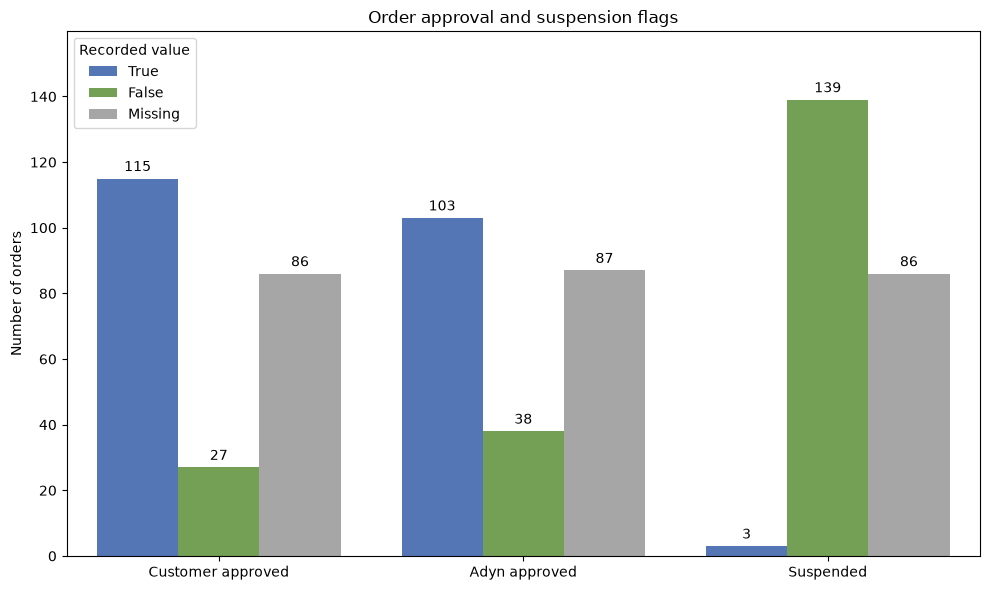

In [32]:
fig = plot_approval_flags(rx_orders)
plt.show()


In [ ]:
fig_refills = plot_refills(rx_orders)
fig_box_refills = plot_refills(rx_orders, kind="box")
fig_rx_quantity = plot_quantity(rx_orders)
fig_rx_quantity_bc = plot_quantity(rx_orders, by_bc=True)
fig_rx_orders_bc = plot_category_counts(rx_orders, "bc_prescribed")
fig_rx_orders_sku = plot_category_counts(rx_orders, "sku")
fig_rx_written_ndc = plot_category_counts(rx_written, "ndc")  # Separate filename from SKU plot.
fig_monthly_orders = plot_monthly_orders(rx_orders)
fig_prescriptions = plot_prescriptions_per_patient(rx_written)
fig_grouped_prescriptions = plot_prescriptions_per_patient(rx_written, grouped=True)
fig_customer_age = plot_customer_age(rx_written, as_of="2026-10-31")  # Change date or omit.
fig_entry_delay = plot_entry_delay(rx_written)
fig_packing_delay = plot_packing_delay("RxPacked", conn=conn)
fig_payment_delay = plot_payment_delay(rx_orders)
fig_payment_delay_adjust = plot_payment_delay(rx_orders, xlim=(0, 50), filename="payment_delay_zoom.png")
fig_state_shipments = plot_shipments_by_state("RxShipments", conn=conn)
plt.show()  # For Matplotlib; call fig.show() for the Plotly map.
fig_state_shipments.show()
plt.close()  # Close a Matplotlib figure when finished to free memory.


In [33]:
rx_orders.columns


Index(['id', 'friendly_order_id', 'customer_id', 'stripe_customer_id',
       'status', 'prescriber_id', 'sku', 'quantity', 'signetur',
       'note_to_pharmacy', 'bc_prescribed', 'rx_submitted_to_adyn_pharmacy',
       'refills_allowed', 'customer_cost', 'stripe_price_id',
       'stripe_invoice_item_id', 'stripe_invoice_id', 'date_order_placed',
       'date_order_paid', 'created_date', 'modified_date', 'days_supply',
       'customer_approved', 'adyn_approved', 'customer_disapproved_reason',
       'adyn_disapproved_reason', 'suspended', 'suspended_reason',
       'customer_visibility', 'appointment_id'],
      dtype='str')

In [4]:
missing

,dtype,n_missing,share_missing,n_unique
id,str,0,0.000000,228
friendly_order_id,str,0,0.000000,228
customer_id,str,0,0.000000,45
stripe_customer_id,str,0,0.000000,45
status,str,206,0.903509,2
prescriber_id,str,0,0.000000,13
sku,str,0,0.000000,14
quantity,int64,0,0.000000,7
signetur,str,0,0.000000,50
note_to_pharmacy,str,0,0.000000,28


In [ ]:
quantities_by_bc


,count,mean,median,std,min,max
bc_prescribed,,,,,,
False,28,2.178571,3.0,0.944911,1,3
True,200,3.140000,3.0,2.042365,1,12


In [8]:
quantities_by_sku

,count,mean,median,std,min,max
sku,,,,,,
AD-BC-ALTAVE00,22,3.136364,3.0,0.639602,3,6
AD-BC-DAYSEE00,43,2.372093,2.0,0.756661,2,4
AD-BC-DEPOTP00,30,1.200000,1.0,0.610257,1,3
AD-BC-DROS03LE,13,3.846154,3.0,1.344504,3,6
AD-BC-EXTERNAL,4,2.250000,2.0,1.500000,1,4
AD-BC-FALMIN20,31,1.516129,1.0,1.150970,1,5
AD-BC-FREE0000,1,3.000000,3.0,NaN,3,3
AD-BC-JUNE20FE,38,6.105263,6.0,1.997153,3,12
AD-BC-NEXT3142,4,3.000000,3.0,0.000000,3,3
